In [1]:
import sklearn

import shap

# a classic housing price dataset
X, y = shap.datasets.california(n_points=1000)

X100 = shap.utils.sample(X, 100)  # 100 instances for use as the background distribution

# a simple linear model
model = sklearn.linear_model.LinearRegression()
model.fit(X, y)

LinearRegression()

In [ ]:
print("Model coefficients:\n")
for i in range(X.shape[1]):
    print(X.columns[i], "=", model.coef_[i].round(5))

Model coefficients:

MedInc = 0.42563
HouseAge = 0.01033
AveRooms = -0.1161
AveBedrms = 0.66385
Population = 3e-05
AveOccup = -0.26096
Latitude = -0.46734
Longitude = -0.46272


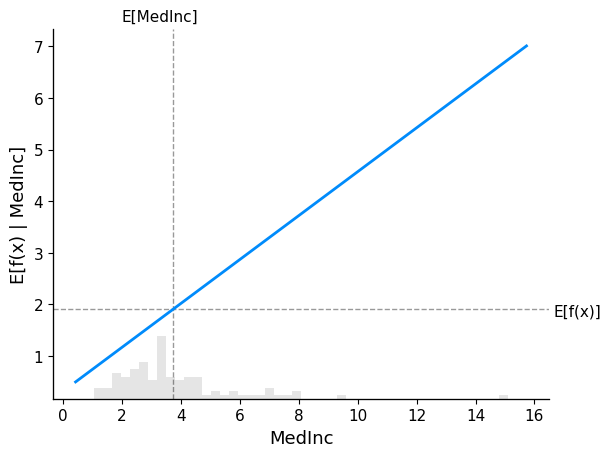

In [ ]:
shap.partial_dependence_plot(
    "MedInc",
    model.predict,
    X100,
    ice=False,
    model_expected_value=True,
    feature_expected_value=True,
)

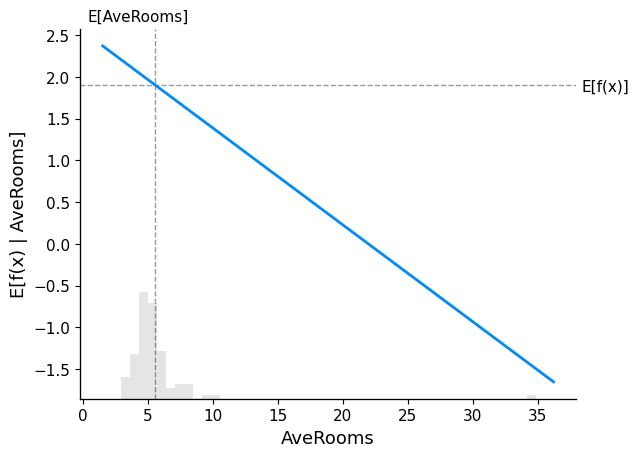

In [ ]:
shap.partial_dependence_plot(
    "AveRooms",
    model.predict,
    X100,
    ice=False,
    model_expected_value=True,
    feature_expected_value=True,
)

In [ ]:
import numpy as np
model.fit(X, y)
y_pred = model.predict(X100)
np.mean(y_pred)

np.float64(1.9035338119654122)

ExactExplainer explainer: 1001it [00:13, 26.55it/s]                         


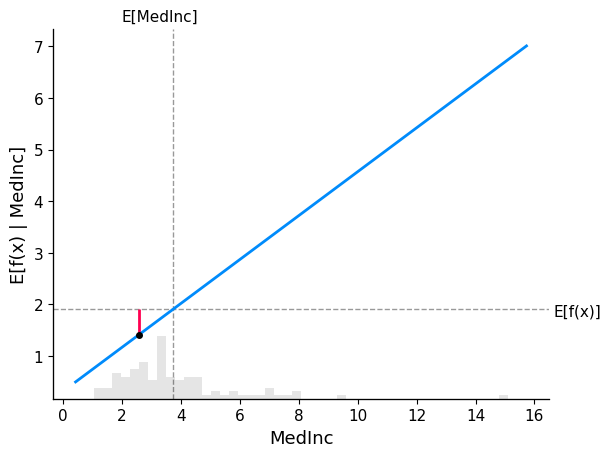

In [ ]:
# compute the SHAP values for the linear model
explainer = shap.Explainer(model.predict, X100)
shap_values = explainer(X)

# make a standard partial dependence plot
sample_ind = 20
shap.partial_dependence_plot(
    "MedInc",
    model.predict,
    X100,
    model_expected_value=True,
    feature_expected_value=True,
    ice=False,
    shap_values=shap_values[sample_ind : sample_ind + 1, :],
)

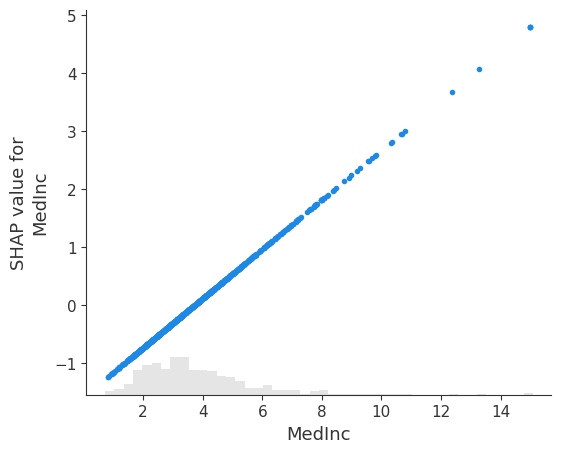

In [ ]:
shap.plots.scatter(shap_values[:, "MedInc"])

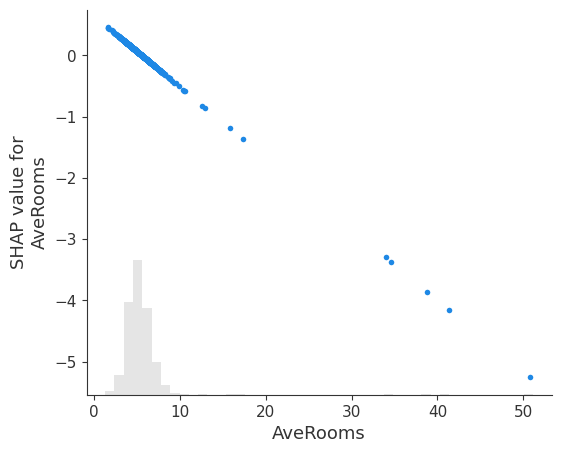

In [ ]:
shap.plots.scatter(shap_values[:, "AveRooms"])

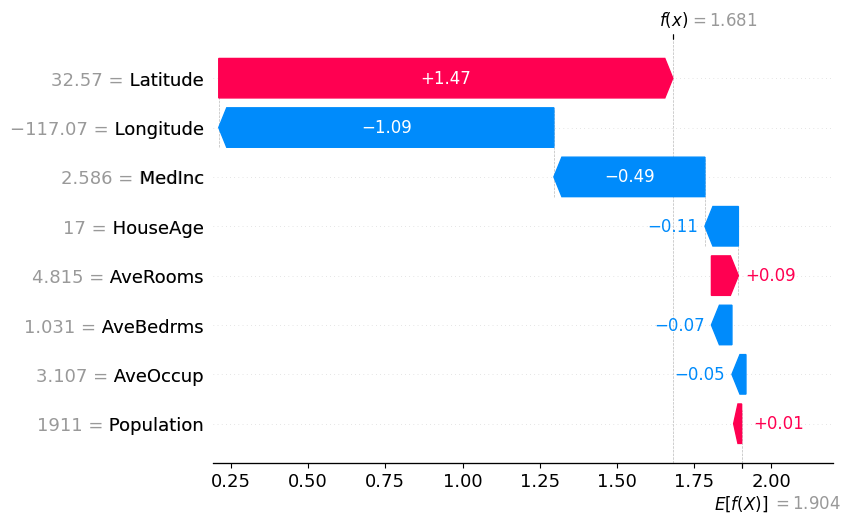

In [ ]:
# @설명하려는 특정 예측값($f(x)$)과 기본(평균) 모델 출력값($E[f(X)]$) 사이의 차이는 모든 입력 특성들의 SHAP 값들을 모두 더한 것과 항상 같다.
# the waterfall_plot shows how we get from shap_values.base_values to model.predict(X)[sample_ind]
shap.plots.waterfall(shap_values[sample_ind], max_display=14)

In [ ]:
# @ sample_ind에서 각 입력변수의 shap 값을 구하면
display(shap_values[sample_ind])

.values =
array([-0.48900816, -0.10840999,  0.08734303, -0.06647713,  0.01402258,
       -0.04536997,  1.47024547, -1.08511549])

.base_values =
np.float64(1.9035338119654142)

.data =
array([ 2.58590000e+00,  1.70000000e+01,  4.81463415e+00,  1.03089431e+00,
        1.91100000e+03,  3.10731707e+00,  3.25700000e+01, -1.17070000e+02])

In [ ]:
shap_values[sample_ind].values

array([-0.48900816, -0.10840999,  0.08734303, -0.06647713,  0.01402258,
       -0.04536997,  1.47024547, -1.08511549])

In [ ]:
shap_values[sample_ind].base_values

np.float64(1.9035338119654142)

In [ ]:
np.sum(shap_values[sample_ind].values) + shap_values[sample_ind].base_values

np.float64(1.680764153149626)

In [ ]:
model.predict(shap_values[sample_ind].data.reshape(1, -1))

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([1.68076415])

In [ ]:
assert np.isclose(np.sum(shap_values[sample_ind].values) + shap_values[sample_ind].base_values, model.predict(shap_values[sample_ind].data.reshape(1, -1)))

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 84.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.2/47.2 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 91.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 97.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 52.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 74.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.1/780.1 kB 38.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 91.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.7/270.7 kB 16.3 MB/s eta 0:00:00
  Created wheel for dash-cytoscape: filename=dash_cytoscape-1.0.2-py3-none-any.whl size=4010717 sha256=7112cacdf09513042cd675a2b1fae937af9fdc839f31b5ebea5bf155cdd503e3
  Stored in directory: /root/.cache/pip/wheels/0c/db/f6/9dcb225e9adf45dfef713542769

ExactExplainer explainer: 1001it [00:12, 17.30it/s]                         


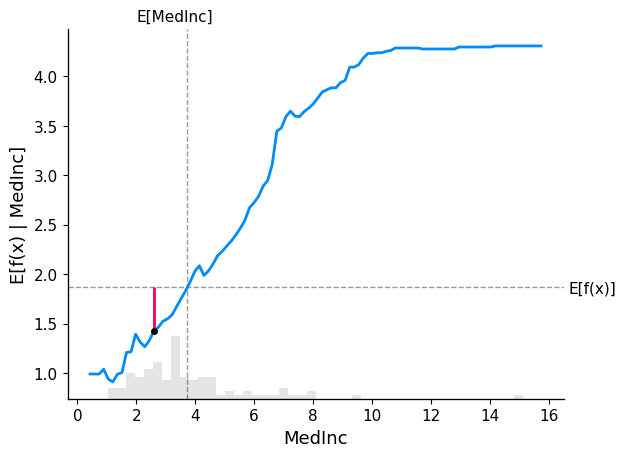

In [ ]:
!pip install interpret
# fit a GAM model to the data
import interpret.glassbox

model_ebm = interpret.glassbox.ExplainableBoostingRegressor(interactions=0)
model_ebm.fit(X, y)

# explain the GAM model with SHAP
explainer_ebm = shap.Explainer(model_ebm.predict, X100)
shap_values_ebm = explainer_ebm(X)

# make a standard partial dependence plot with a single SHAP value overlaid
fig, ax = shap.partial_dependence_plot(
    "MedInc",
    model_ebm.predict,
    X100,
    model_expected_value=True,
    feature_expected_value=True,
    show=False,
    ice=False,
    shap_values=shap_values_ebm[sample_ind : sample_ind + 1, :],
)

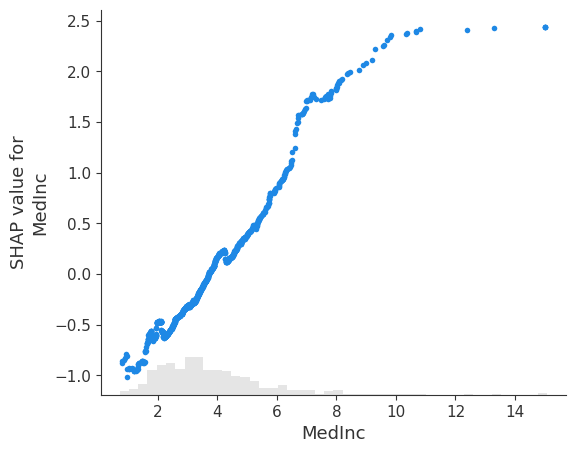

In [ ]:
shap.plots.scatter(shap_values_ebm[:, "MedInc"])

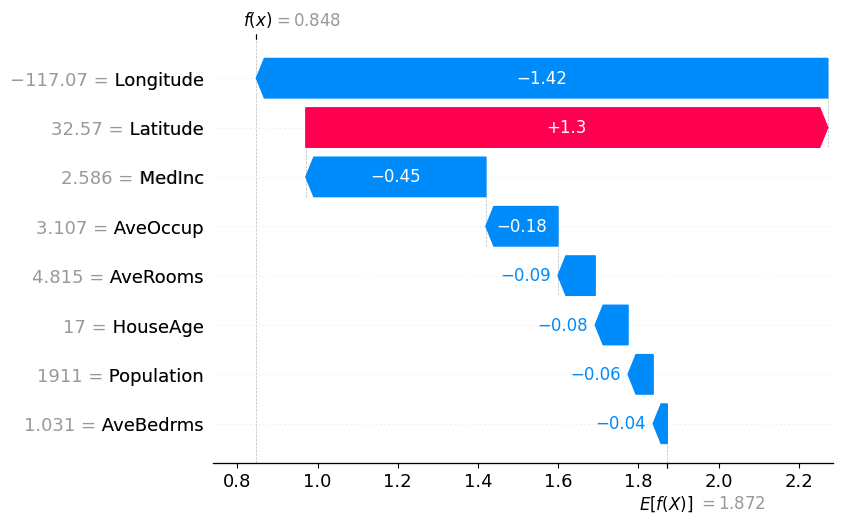

In [ ]:
# the waterfall_plot shows how we get from explainer.expected_value to model.predict(X)[sample_ind]
shap.plots.waterfall(shap_values_ebm[sample_ind])

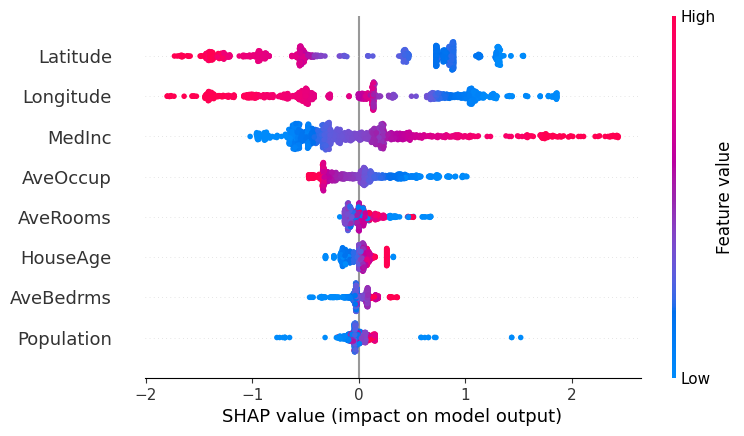

In [ ]:
# the beeswarm plot displays SHAP values for each feature across all examples,
# with colors indicating how the SHAP values correlate with feature values
shap.plots.beeswarm(shap_values_ebm)

In [ ]:
# @ a simple linear model, model = sklearn.linear_model.LinearRegression()
# shap.plots.beeswarm(shap_values)

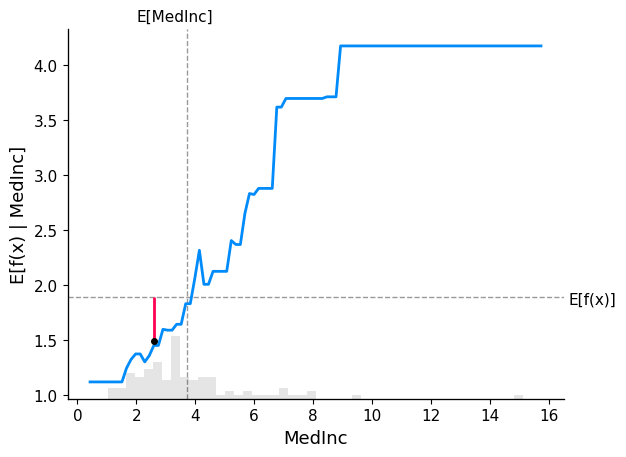

In [ ]:
import xgboost
import shap

# train XGBoost model
model_xgb = xgboost.XGBRegressor(n_estimators=100, max_depth=2, enable_categorical=False).fit(X, y)

# explain the GAM model with SHAP
explainer_xgb = shap.Explainer(model_xgb, X100, feature_perturbation='tree_path_dependent')
shap_values_xgb = explainer_xgb(X)

# make a standard partial dependence plot with a single SHAP value overlaid
fig, ax = shap.partial_dependence_plot(
    "MedInc",
    model_xgb.predict,
    X100,
    model_expected_value=True,
    feature_expected_value=True,
    show=False,
    ice=False,
    shap_values=shap_values_xgb[sample_ind : sample_ind + 1, :],
)

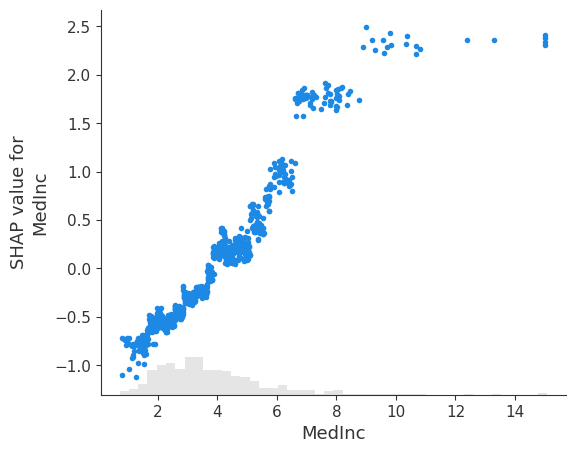

In [ ]:
# @ 득이 올라감에 따라 모델이 예측하는 집값 기여도(SHAP value)가 어떤 곡선을 그리며 상승하는지 정확한 형태(비선형 관계)
# 소득이 약 6을 넘어서면서 기여도가 급격히 상승하다가 8 이후로는 완만해지는 흐름
# 모든 점이 파란색 단색으로 표시되어 있어, 오직 '소득 단 하나'의 영향력만 관찰
shap.plots.scatter(shap_values_xgb[:, "MedInc"])

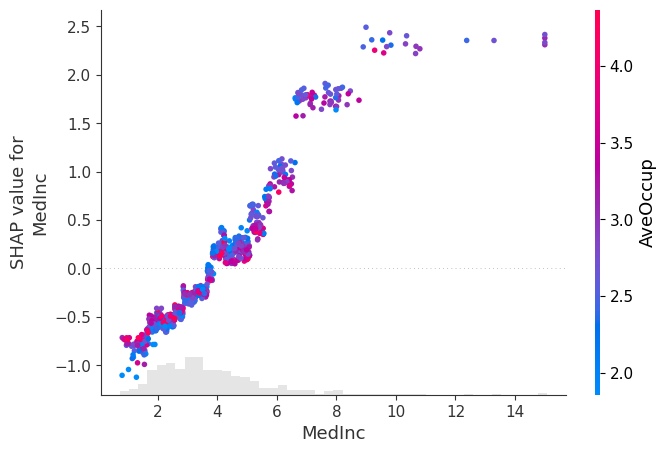

In [ ]:
# @ color=shap_values (자동 상호작용 감지) - MedIn과 가장 상호관계가 있는 AveOccup를 자동 감지
# 그런데 소득이 증가할 때 가구원 수가 적어야 집값이 더 탄력을 받는다(더 비싸다)"는 변수 간의 입체적인 상호작용
'''
소득 중간값(MedInc)이 4인 지점을 세로로 길게 보면, 파란색 점(가구원 수가 적은 집, 약 2.0명)들은 위쪽에 위치해 있고
분홍/빨간색 점(가구원 수가 많은 집, 약 3.5명 이상)들은 아래쪽에 위치하니,

이는 곧 "소득이 똑같이 4만 달러 수준이더라도, 가구원 수가 적은(쾌적한) 집일 때 모델은 집값을 더 높게 예측하고,
가구원 수가 너무 많은 집일 때는 집값을 더 낮게 예측한다"는 숨겨진 규칙을 보여주는 것
'''

shap.plots.scatter(shap_values_xgb[:, "MedInc"], color=shap_values)

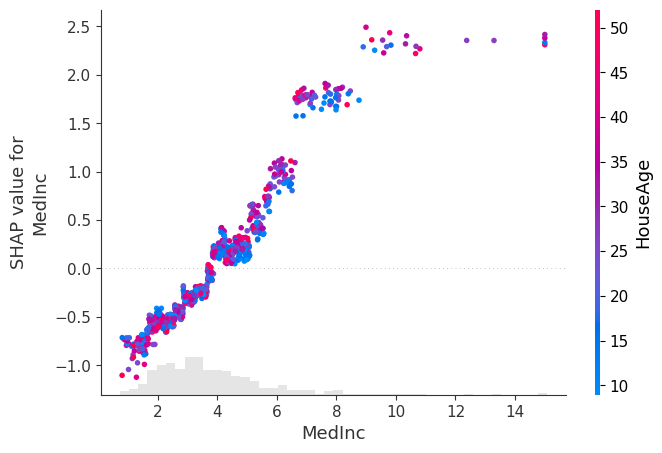

In [ ]:
# 'AveOccup'가 아니라 집값 연식('HouseAge')과의 상호작용을 보고 싶을 때
shap.plots.scatter(shap_values_xgb[:, "MedInc"], color=shap_values_xgb[:, "HouseAge"])

In [2]:
# a classic adult census dataset price dataset
X_adult, y_adult = shap.datasets.adult()

# a simple linear logistic model
model_adult = sklearn.linear_model.LogisticRegression(max_iter=10000)
model_adult.fit(X_adult, y_adult)


def model_adult_proba(x):
    return model_adult.predict_proba(x)[:, 1]


def model_adult_log_odds(x):
    p = model_adult.predict_log_proba(x)
    return p[:, 1] - p[:, 0]

In [5]:
y_adult

array([False, False, False, ..., False, False,  True])

In [11]:
X_adult.head()

,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39
3,53.0,4,7.0,2,6,4,2,1,0.0,0.0,40.0,39
4,28.0,4,13.0,2,10,5,2,0,0.0,0.0,40.0,5


In [26]:
model_adult.predict_proba(X_adult)[:, 1]

array([0.13052913, 0.37013367, 0.03897361, ..., 0.02407019, 0.02645726,
       0.98057175])

In [40]:
model_adult.predict_proba(X_adult)

array([[0.86947087, 0.13052913],
       [0.62986633, 0.37013367],
       [0.96102639, 0.03897361],
       ...,
       [0.97592981, 0.02407019],
       [0.97354274, 0.02645726],
       [0.01942825, 0.98057175]])

In [39]:
model_adult.predict_log_proba(X_adult)

array([[-0.13987045, -2.03615883],
       [-0.46224766, -0.99389107],
       [-0.03975341, -3.24487047],
       ...,
       [-0.02436461, -3.72678105],
       [-0.02681355, -3.63222479],
       [-3.94102703, -0.01961946]])

In [41]:
p = model_adult.predict_log_proba(X_adult)
p[:, 1] - p[:, 0]

array([-1.89628838, -0.53164341, -3.20511706, ..., -3.70241644,
       -3.60541124,  3.92140757])

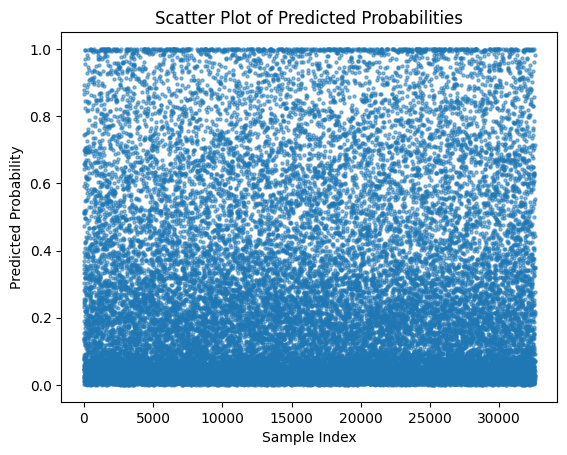

In [29]:
probabilities = model_adult.predict_proba(X_adult)[:, 1]
indices = np.arange(len(probabilities))

plt.scatter(indices, probabilities, s=5, alpha=0.5)
plt.xlabel("Sample Index")
plt.ylabel("Predicted Probability")
plt.title("Scatter Plot of Predicted Probabilities")
plt.show()

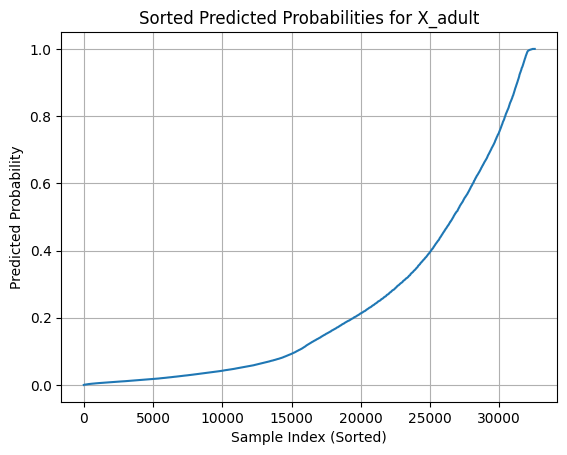

In [28]:
# Get the probabilities
probabilities = model_adult.predict_proba(X_adult)[:, 1]
# Sort the probabilities in ascending order
sorted_probabilities = np.sort(probabilities)

# Create indices for the sorted probabilities
indices = np.arange(len(sorted_probabilities))

# Plot the sorted probabilities
plt.plot(indices, sorted_probabilities)
plt.xlabel("Sample Index (Sorted)")
plt.ylabel("Predicted Probability")
plt.title("Sorted Predicted Probabilities for X_adult")
plt.grid(True)
plt.show()

### 모든 feature에 대한 S 형태의 비선형 확률곡선을 개별 feature에 따라 시각화

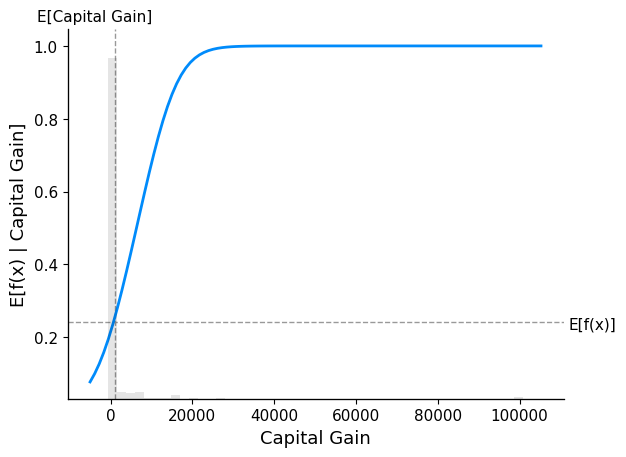

In [31]:
# make a standard partial dependence plot
sample_ind = 18
fig, ax = shap.partial_dependence_plot(
    "Capital Gain",
    model_adult_proba,
    X_adult,
    model_expected_value=True,
    feature_expected_value=True,
    show=False,
    ice=False,
)

In [15]:
np.mean(model_adult.predict_proba(X_adult)[:, 1])

np.float64(0.240801859220977)

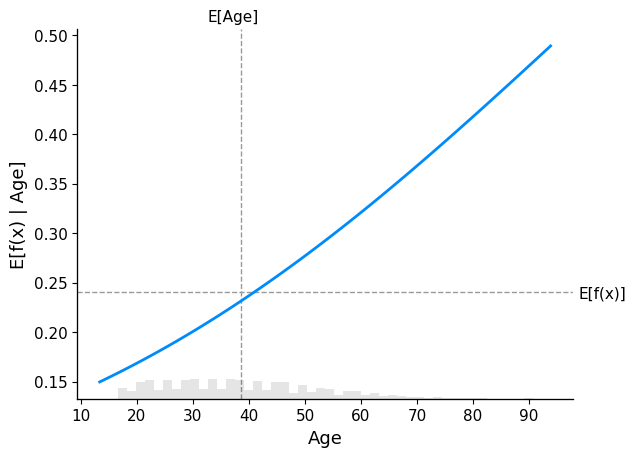

In [35]:
# make a standard partial dependence plot
sample_ind = 18
fig, ax = shap.partial_dependence_plot(
    "Age",
    model_adult_proba,
    X_adult,
    model_expected_value=True,
    feature_expected_value=True,
    show=False,
    ice=False,
)

In [13]:
# compute the SHAP values for the linear model
background_adult = shap.maskers.Independent(X_adult, max_samples=100)
explainer = shap.Explainer(model_adult_proba, background_adult)
shap_values_adult = explainer(X_adult[:1000])

PermutationExplainer explainer: 1001it [00:44, 19.70it/s]                          


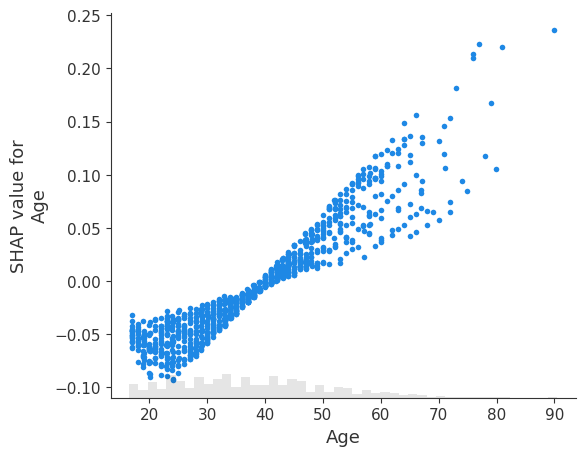

In [34]:
#@로지스틱 회귀 모델 자체는 선형적이지만, 최종 결과를 '확률' 단위로 변환해 버리는 순간 더하기 규칙이 깨지면서
# @ 변수 간의 복잡한 얽힘(상호작용)이 발생하며 SHAP은 이 현상을 정확하게 짚어내어 시각화
shap.plots.scatter(shap_values_adult[:, "Age"])

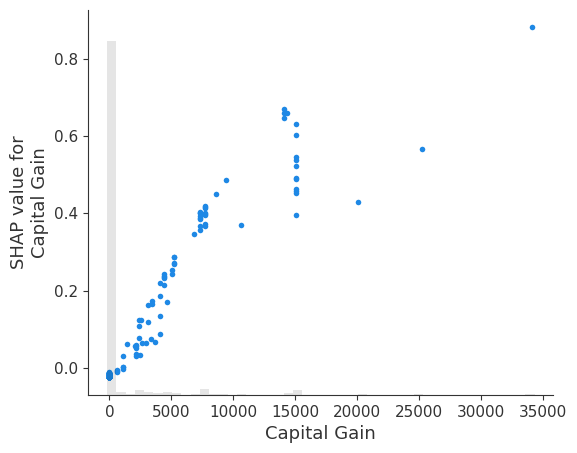

In [36]:
shap.plots.scatter(shap_values_adult[:, "Capital Gain"])

In [37]:
# compute the SHAP values for the linear model
explainer_log_odds = shap.Explainer(model_adult_log_odds, background_adult)
shap_values_adult_log_odds = explainer_log_odds(X_adult[:1000])

PermutationExplainer explainer: 1001it [00:39, 18.46it/s]                          


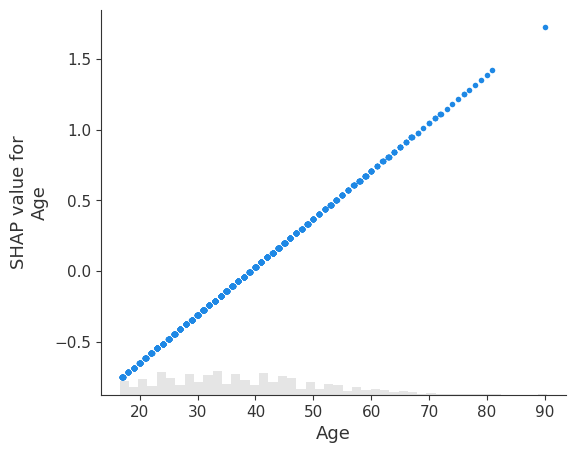

In [38]:
shap.plots.scatter(shap_values_adult_log_odds[:, "Age"])

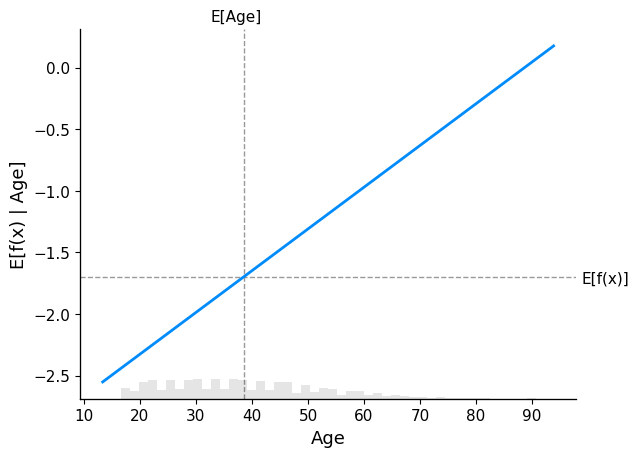

In [42]:
# make a standard partial dependence plot
sample_ind = 18
fig, ax = shap.partial_dependence_plot(
    "Age",
    model_adult_log_odds,
    X_adult,
    model_expected_value=True,
    feature_expected_value=True,
    show=False,
    ice=False,
)

In [48]:
import xgboost
# train XGBoost model
model = xgboost.XGBClassifier(n_estimators=100, max_depth=2, enable_categorical=False).fit(X_adult, y_adult * 1)

# compute SHAP values
explainer = shap.Explainer(model, background_adult, feature_perturbation='tree_path_dependent')
shap_values = explainer(X_adult.values)

# set a display version of the data to use for plotting (has string values)
shap_values.display_data = shap.datasets.adult(display=True)[0].values

In [50]:
shap_values

.values =
array([[ 5.68759791e-01, -2.19147226e-01,  6.53553513e-01, ...,
        -8.85927806e-02, -1.30710225e-01,  8.21233058e-03],
       [ 7.64647865e-01, -2.21158539e-01,  7.17674981e-01, ...,
        -7.88211183e-02, -1.04307393e+00,  1.29758907e-02],
       [ 5.17657595e-01,  7.46933456e-03, -2.64550834e-01, ...,
        -8.85927806e-02, -1.14294756e-01,  1.29758907e-02],
       ...,
       [ 8.52537311e-01,  7.46933456e-03, -2.61145446e-01, ...,
        -9.24779553e-02, -1.04135449e-01,  8.21233058e-03],
       [-1.58796689e+00, -1.71600987e-03, -2.03335318e-01, ...,
        -8.74169696e-02, -1.10524097e+00,  4.80076192e-03],
       [ 6.48404599e-01,  1.12667594e-01, -3.70954677e-01, ...,
        -6.21881159e-02, -7.22586971e-02, -2.70521120e-04]])

.base_values =
array([-2.21275629, -2.21275629, -2.21275629, ..., -2.21275629,
       -2.21275629, -2.21275629])

.data =
array([[39.,  7., 13., ...,  0., 40., 39.],
       [50.,  6., 13., ...,  0., 13., 39.],
       [38.,  4.,  9.,

In [49]:
shap_values.display_data

array([[39.0, ' State-gov', 13.0, ..., 0.0, 40.0, ' United-States'],
       [50.0, ' Self-emp-not-inc', 13.0, ..., 0.0, 13.0,
        ' United-States'],
       [38.0, ' Private', 9.0, ..., 0.0, 40.0, ' United-States'],
       ...,
       [58.0, ' Private', 9.0, ..., 0.0, 40.0, ' United-States'],
       [22.0, ' Private', 9.0, ..., 0.0, 20.0, ' United-States'],
       [52.0, ' Self-emp-inc', 9.0, ..., 0.0, 40.0, ' United-States']],
      dtype=object)

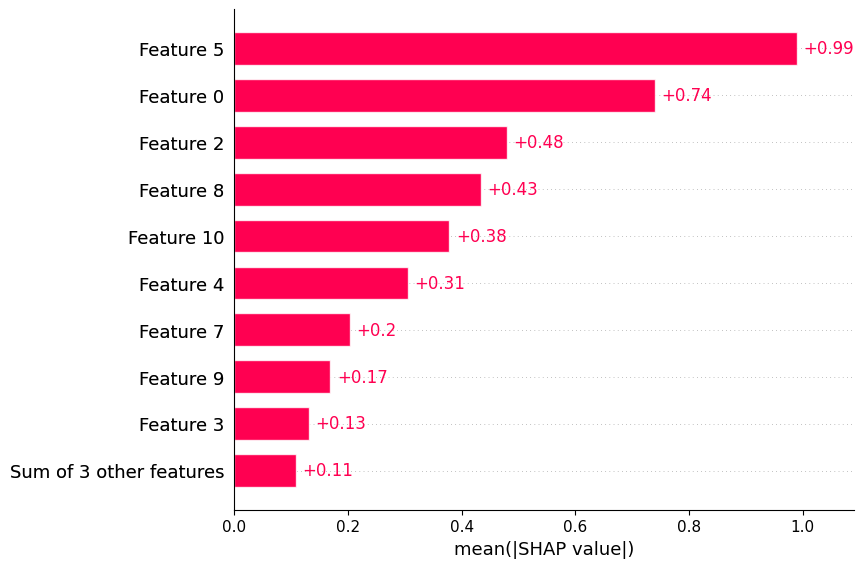

In [58]:
shap.plots.bar(shap_values)

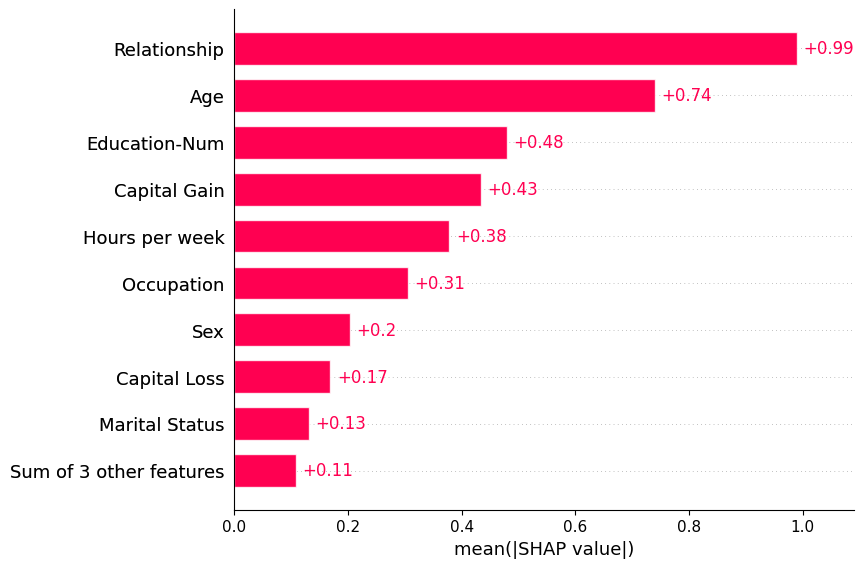

In [59]:
shap_values.feature_names = X_adult.columns
shap.plots.bar(shap_values)

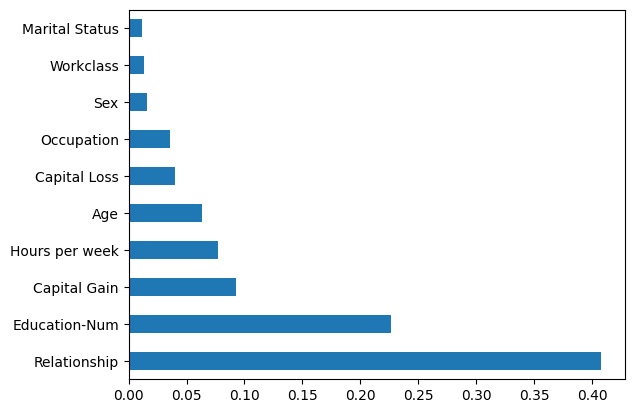

In [56]:
import pandas as pd
# 2. 내장 feature_importances_ 꺼내기
importances = model.feature_importances_
# 3. 보기 좋게 데이터프레임으로 만들어 시각화
feat_importances = pd.Series(importances, index=X_adult.columns)
feat_importances.nlargest(10).plot(kind='barh')
plt.show()

Scikit-Learn의 중요도(별첨 2)는 "데이터를 분류할 때 의사결정 나무가 이 변수의 경계선을 얼마나 자주 써먹었는가"를 뜻하며, 구조적 특성상 연속형 변수나 카테고리가 많은 변수가 다소 유리하게 평가됩니다.

SHAP의 중요도(별첨 1)는 "실제 최종 예측 확률을 뒤흔드는 데 이 변수가 실질적으로 행사한 순수한 지분의 평균 크기"를 뜻하므로 수학적으로 훨씬 정교하고 왜곡이 없습니다.

💡 실무 팁: 그래서 요즘 머신러닝 업계에서는 모델의 자체 내장 중요도(별첨2)만 믿기보다는, 다소 연산 시간이 걸리더라도 더 객관적이고 정확한 **SHAP 중요도**를 훨씬 신뢰하는 추세입니다!

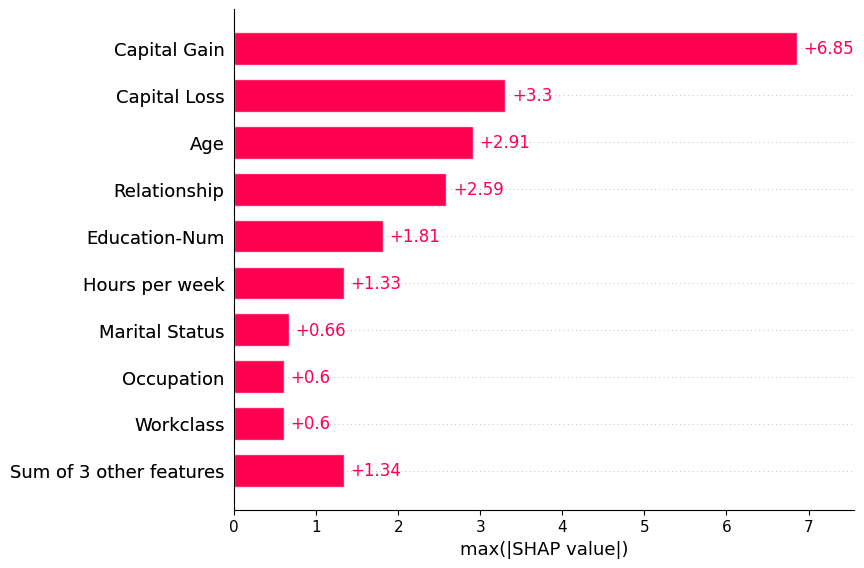

In [60]:
shap.plots.bar(shap_values.abs.max(0))

평균의 함정에 빠지지 말고, 가끔 터지는 '한 방'의 크기(최댓값)도 주목하자!
나이가 많다고 5만불이상이라고 말하기 어렵고 평균적으로 그렇다는 이야기지 그러나 주식투자로 한 방(대박 혹은 쪽박, capital gain, capital loss)은 다르다

'절댓값 평균'이 놓치는 것: 가끔 터지는 대박 (Infrequent but High Magnitude)
- mean(|SHAP value|)은 모든 사람들의 기여도를 평균 낸 것입니다. 이 방식은 대다수의 사람에게 늘 영향을 미치는 변수(예: 나이, 가족 관계 등)를 찾아내는 데는 아주 좋습니다.
- 하지만 '자본 이득(Capital Gain)'이나 '자본 손실(Capital Loss)' 같은 변수는 성격이 완전히 다릅니다.대부분의 평범한 사람들: 주식 대박이나 부동산 대박이 나지 않으므로 자본 이득이 $0$입니다. 이들의 SHAP 값은 $0$에 가깝습니다.아주 극소수의 부자들: 자본 이득이 수억 원에 달해, 이 변수 하나만으로 고소득자 확률이 $100%$로 치솟습니다. (SHAP 값이 엄청나게 큽니다.)이걸 '평균' 내버리면 어떻게 될까요?
- 대다수의 $0$ 때문에 극소수의 엄청나게 큰 기여도가 희석되어, 평균적인 중요도는 낮게 나와버립니다. (실제로 바로 전 그래프에서 Capital Gain은 중요도 4위, Capital Loss는 8위에 머물렀죠.)

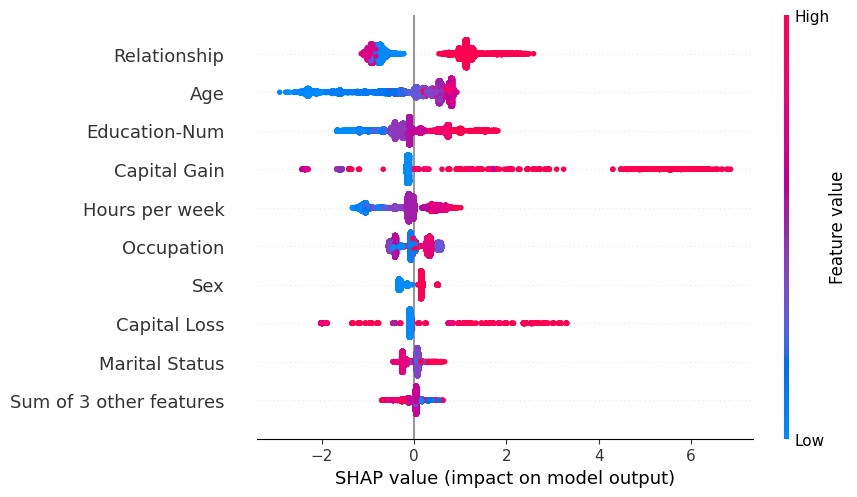

In [61]:
shap.plots.beeswarm(shap_values)

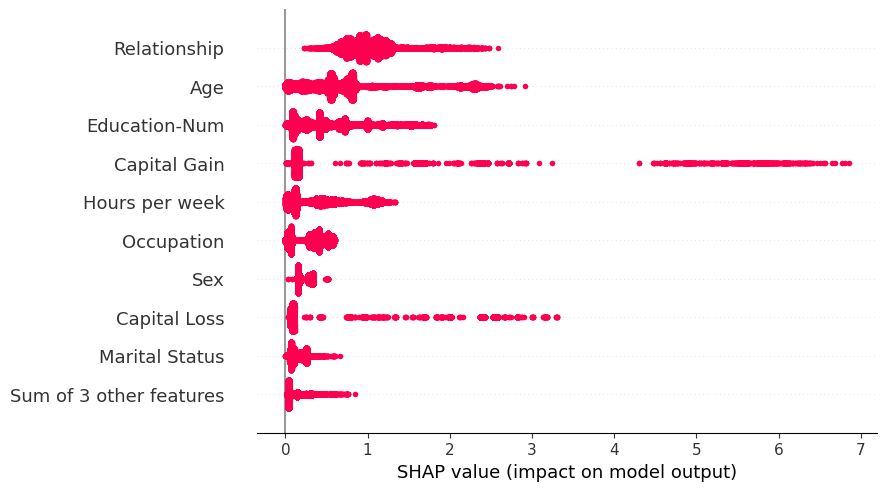

In [62]:
shap.plots.beeswarm(shap_values.abs, color="shap_red")

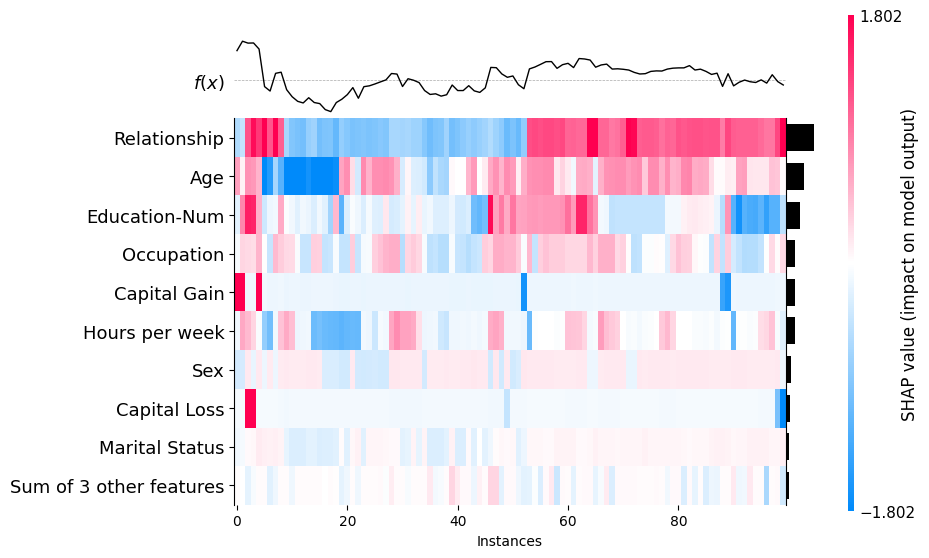

<Axes: xlabel='Instances'>

In [63]:
shap.plots.heatmap(shap_values[:100])

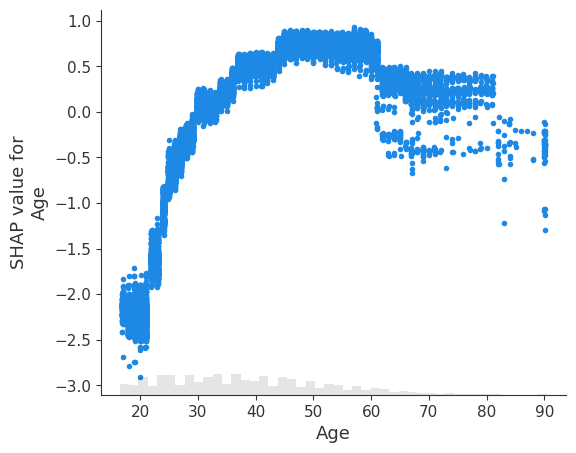

In [64]:
shap.plots.scatter(shap_values[:, "Age"])

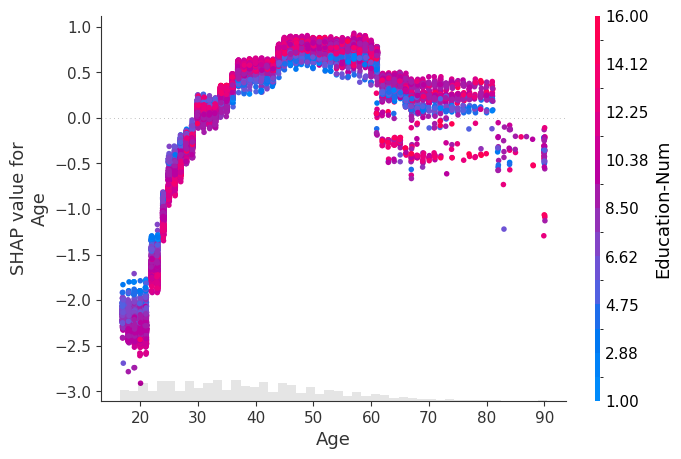

In [66]:
shap.plots.scatter(shap_values[:, "Age"], color=shap_values)

In [69]:
X_adult.head()

,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39
3,53.0,4,7.0,2,6,4,2,1,0.0,0.0,40.0,39
4,28.0,4,13.0,2,10,5,2,0,0.0,0.0,40.0,5


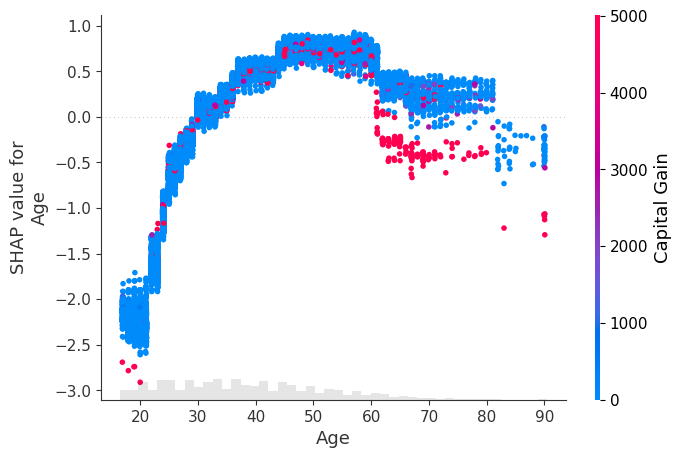

In [67]:
shap.plots.scatter(shap_values[:, "Age"], color=shap_values[:, "Capital Gain"])

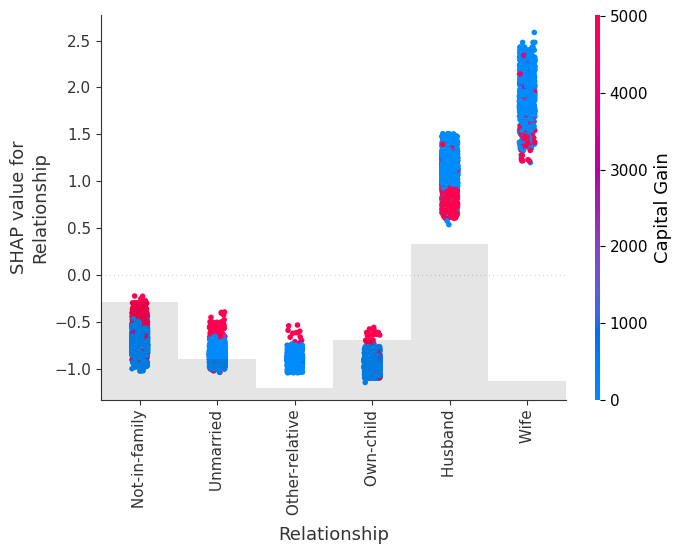

In [68]:
shap.plots.scatter(shap_values[:, "Relationship"], color=shap_values)

In [70]:
clustering = shap.utils.hclust(X_adult, y_adult)

145it [00:10,  1.69s/it]                 


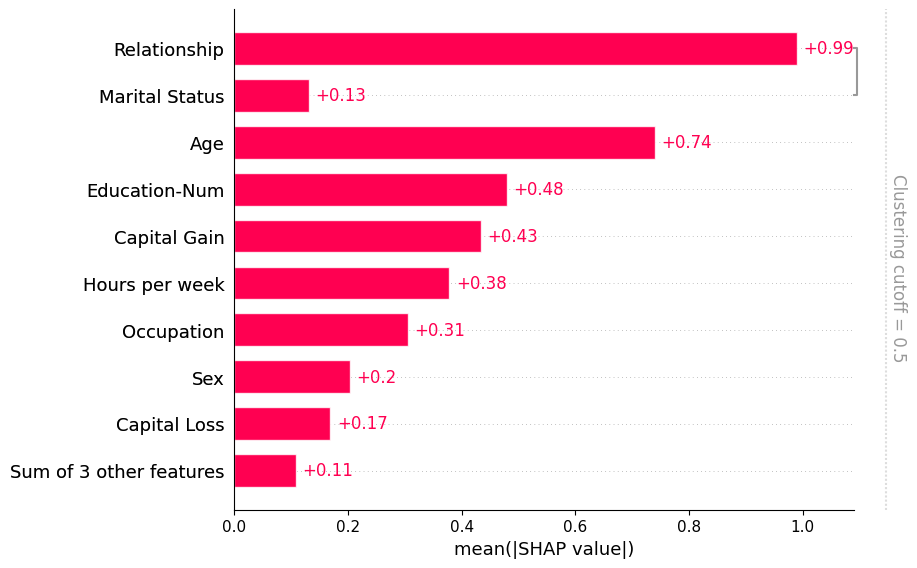

In [71]:
shap.plots.bar(shap_values, clustering=clustering)

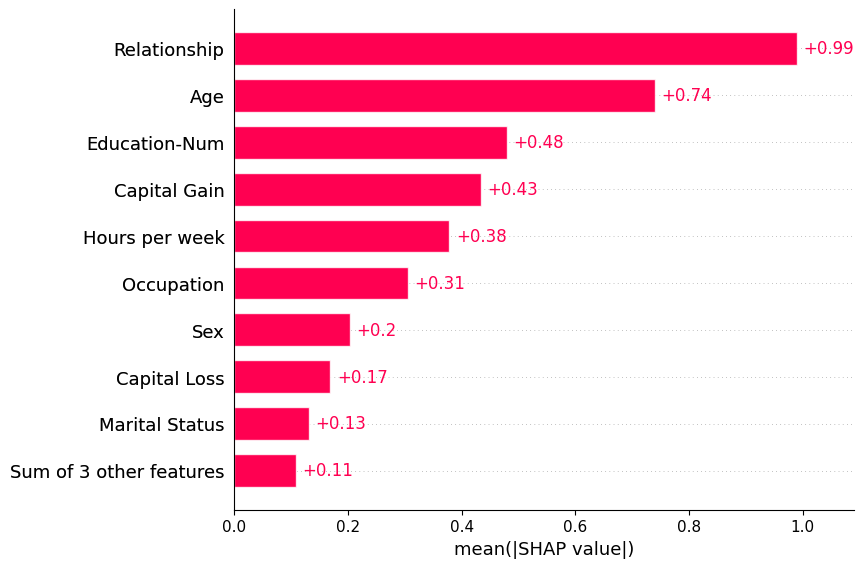

In [74]:
shap_values.feature_names = X_adult.columns
shap.plots.bar(shap_values)

>> [ 거리 = 0 ] ------------------------------------ [ 거리 = 1 ]

>>   (완벽히 중복)      (어느 정도 연관됨)       (완전히 남남)

>>               ▲                      ▲


>>           Cutoff 0.5             Cutoff 0.8

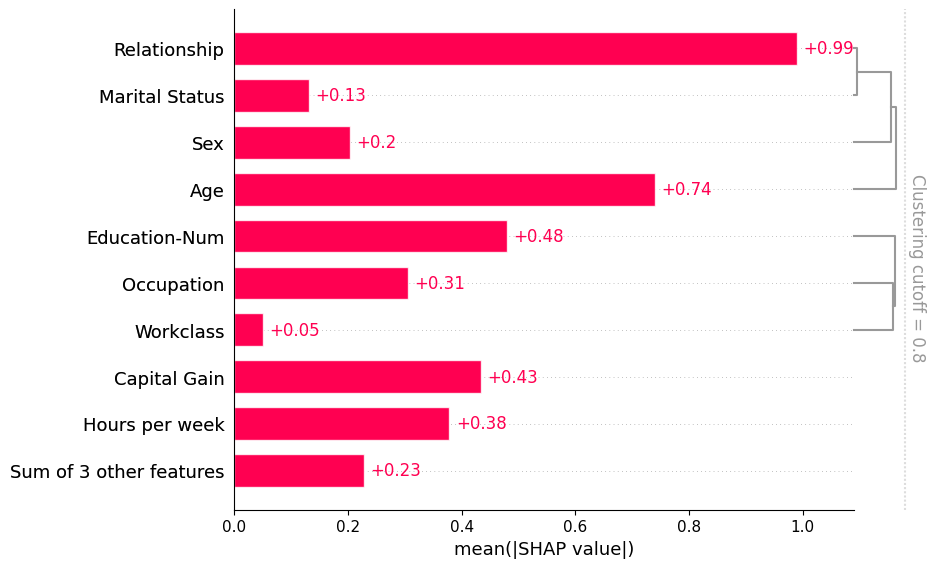

In [75]:
shap.plots.bar(shap_values, clustering=clustering, clustering_cutoff=0.8)

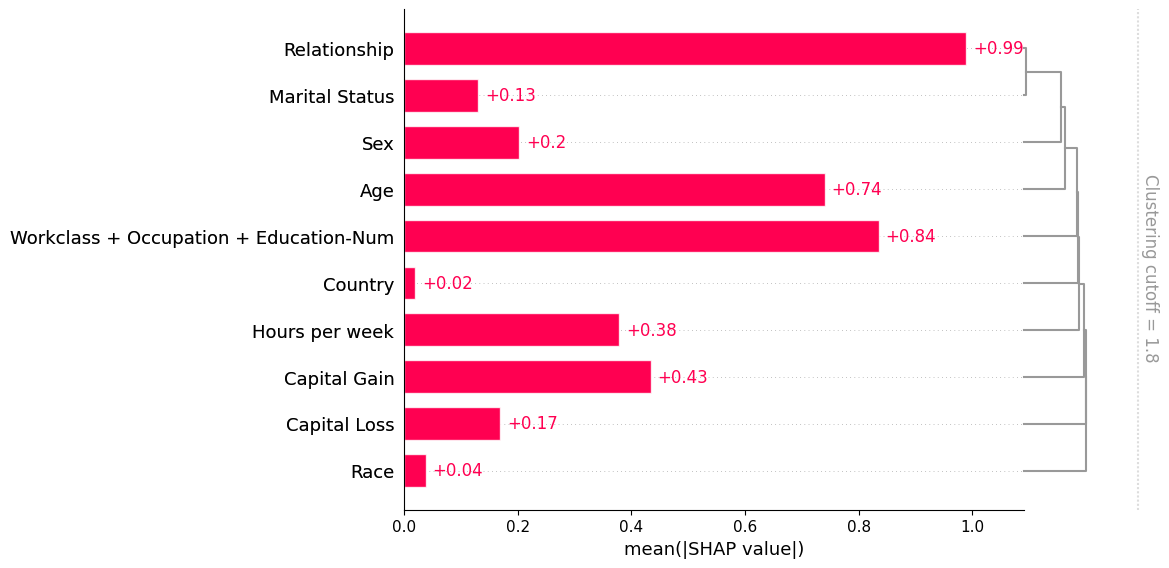

In [76]:
shap.plots.bar(shap_values, clustering=clustering, clustering_cutoff=1.8)

In [72]:
X_adult

,Age,Workclass,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country
0,39.0,7,13.0,4,1,0,4,1,2174.0,0.0,40.0,39
1,50.0,6,13.0,2,4,4,4,1,0.0,0.0,13.0,39
2,38.0,4,9.0,0,6,0,4,1,0.0,0.0,40.0,39
3,53.0,4,7.0,2,6,4,2,1,0.0,0.0,40.0,39
4,28.0,4,13.0,2,10,5,2,0,0.0,0.0,40.0,5
...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27.0,4,12.0,2,13,5,4,0,0.0,0.0,38.0,39
32557,40.0,4,9.0,2,7,4,4,1,0.0,0.0,40.0,39
32558,58.0,4,9.0,6,1,1,4,0,0.0,0.0,40.0,39
32559,22.0,4,9.0,4,1,3,4,1,0.0,0.0,20.0,39


In [73]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

# VIF를 계산할 데이터프레임 (X_adult)의 모든 컬럼에 대해 VIF를 계산합니다.
# 상수항이 없는 모델의 VIF 계산을 위해 add_constant를 사용합니다.
X_adult_const = pd.DataFrame(X_adult)
X_adult_const = X_adult_const.astype(float) # Ensure all columns are numeric
X_adult_const['intercept'] = 1 # Add a constant term

vif_data = pd.DataFrame()
vif_data['feature'] = X_adult_const.columns
vif_data['VIF'] = [variance_inflation_factor(X_adult_const.values, i) for i in range(X_adult_const.shape[1])]

# 'intercept'는 VIF 해석에 필요하지 않으므로 제거합니다.
vif_data = vif_data[vif_data['feature'] != 'intercept']

# VIF 값을 기준으로 내림차순 정렬하여 출력합니다.
display(vif_data.sort_values(by='VIF', ascending=False))

,feature,VIF
7,Sex,1.193577
5,Relationship,1.169862
3,Marital Status,1.164387
10,Hours per week,1.127551
1,Workclass,1.092782
0,Age,1.089151
4,Occupation,1.086267
2,Education-Num,1.058218
6,Race,1.033711
8,Capital Gain,1.029739


In [77]:
import datasets
import numpy as np
import scipy as sp
import torch
import transformers

# load a BERT sentiment analysis model
tokenizer = transformers.DistilBertTokenizerFast.from_pretrained("distilbert-base-uncased")
model = transformers.DistilBertForSequenceClassification.from_pretrained(
    "distilbert-base-uncased-finetuned-sst-2-english"
).cuda()


# define a prediction function
def f(x):
    tv = torch.tensor([tokenizer.encode(v, padding="max_length", max_length=500, truncation=True) for v in x]).cuda()
    outputs = model(tv)[0].detach().cpu().numpy()
    scores = (np.exp(outputs).T / np.exp(outputs).sum(-1)).T
    val = sp.special.logit(scores[:, 1])  # use one vs rest logit units
    return val


# build an explainer using a token masker
explainer = shap.Explainer(f, tokenizer)

# explain the model's predictions on IMDB reviews
imdb_train = datasets.load_dataset("imdb")["train"]
shap_values = explainer(imdb_train[:10], fixed_context=1, batch_size=2)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

AssertionError: Torch not compiled with CUDA enabled

In [ ]:
# plot a sentence's explanation
shap.plots.text(shap_values[2])

In [ ]:
shap.plots.bar(shap_values.abs.mean(0))

In [ ]:
shap.plots.bar(shap_values.abs.sum(0))